# 06 Final evaluation

Every system on the test split, which nothing before this notebook used.

- B0: most popular courses
- B1: CF only
- B2: content only (TF-IDF, Sentence-BERT, OpenAI)
- H1: hybrid (CF + content + prerequisite graph), also without the graph
- H2: the H1 shortlist reranked by an LLM, with prompt v1 and v2

Recall@5 is the share of a student's hidden next courses that land in their top 5. I also count it on finished courses only, and report interest fit, picks above the student's level, skipped prerequisites and catalog coverage. The LLM rows use 300 students with a history and 100 new students, so compare them with H1 on those same students.

In [1]:
# Step 0: setup (works in Colab and on a laptop)
import os, sys
from pathlib import Path

# Colab: where the project folder sits in Google Drive
DRIVE_PROJECT = "/content/drive/MyDrive/LearnPath"

if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path(DRIVE_PROJECT)
else:
    PROJECT_DIR = Path.cwd().parent   # running from the notebooks/ folder

assert (PROJECT_DIR / "src" / "learnpath").exists(), f"Project folder not found: {PROJECT_DIR}"
os.environ["LEARNPATH_DIR"] = str(PROJECT_DIR)
sys.path.insert(0, str(PROJECT_DIR / "src"))
print("Project folder:", PROJECT_DIR)

Mounted at /content/drive
Project folder: /content/drive/MyDrive/LearnPath


In [2]:
# Step 1: load everything
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from learnpath import config, experiment as ex, graph, llm, retrieval, plots
from learnpath.hybrid import Recommender
from learnpath.evaluate import evaluate_lists

plots.apply_style()
courses, students, inter, cold, cold_truth = ex.load_data()
PG = graph.build_prereq_graph(courses)
spaces = retrieval.available_spaces(courses)
params = ex.load_params()
missing = [s for s in spaces if s not in params]
assert not missing, f"Run notebook 04 first to tune: {missing}"
fit, hist, truth, truth_done = ex.split_context(inter, "test")
cold_test, cold_truth_test = ex.cold_context(cold, cold_truth, "test")
everyone = pd.concat([students, cold], ignore_index=True)
print("Spaces:", list(spaces), "| params:", {k: {kk: round(vv, 3) for kk, vv in v.items()} for k, v in params.items()})

Spaces: ['tfidf', 'sbert', 'openai'] | params: {'tfidf': {'alpha': 0.8, 'cold_pop_weight': 0.5, 'val_recall@5': 0.23}, 'sbert': {'alpha': 1.0, 'cold_pop_weight': 0.5, 'val_recall@5': 0.221}, 'openai': {'alpha': 1.0, 'cold_pop_weight': 0.5, 'val_recall@5': 0.221}}


In [3]:
# Step 2: students with history (all 2,000)
# When a space's best alpha is 1.0, its content side has zero weight. Its hybrid rows would then
# just repeat "B1 CF only" (no graph) and "H1 CF + graph" (with graph), so they're shown once.
def run(rec, studs, hist_, **kw):
    return {st["student_id"]: rec.recommend(st, hist_.get(st["student_id"]), **kw) for st in studs}

rows, lists_by_system, pure_cf = [], {}, []
studs = students.to_dict("records")
for name, space in spaces.items():
    p = params[name]
    rec = Recommender(courses, space, PG, fit, alpha=p["alpha"], cold_pop_weight=p["cold_pop_weight"])
    systems = {f"B2 content ({name})": dict(mode="content", use_graph=False)}
    if p["alpha"] < 1.0:
        systems[f"H1 hybrid without graph ({name})"] = dict(mode="hybrid", use_graph=False)
        systems[f"H1 hybrid ({name})"] = dict(mode="hybrid")
    else:
        pure_cf.append(name)
        if "H1 CF + graph" not in lists_by_system:
            systems["H1 CF + graph"] = dict(mode="hybrid")
    if name == "tfidf":   # these two don't depend on the text model
        systems = {"B0 popular": dict(mode="popular"), "B1 CF only": dict(mode="cf"), **systems}
    for label, kw in systems.items():
        L = run(rec, studs, hist, **kw)
        lists_by_system[label] = L
        s, _ = evaluate_lists(L, truth, students, courses, rec.checker, hist)
        s_done, _ = evaluate_lists(L, truth_done, students, courses)
        rows.append({"system": label, **s, "recall@5_finished": s_done["recall@5"]})
if pure_cf:
    print("Content weight is zero (alpha = 1.0) for:", ", ".join(pure_cf))
warm_table = pd.DataFrame(rows).set_index("system").sort_index()
cols = ["recall@5", "recall@5_ci95", "recall@5_finished", "ndcg@5", "on_interest_share",
        "too_hard_share", "prereq_violation_share", "catalog_coverage"]
warm_table[cols].round(3)

Content weight is zero (alpha = 1.0) for: sbert, openai


,recall@5,recall@5_ci95,recall@5_finished,ndcg@5,on_interest_share,too_hard_share,prereq_violation_share,catalog_coverage
system,,,,,,,,
B0 popular,0.007,0.003,0.008,0.005,0.032,0.000,0.104,0.002
B1 CF only,0.197,0.013,0.189,0.174,0.870,0.108,0.178,0.592
B2 content (openai),0.048,0.007,0.045,0.035,0.770,0.145,0.238,0.403
B2 content (sbert),0.038,0.006,0.035,0.030,0.674,0.137,0.237,0.386
B2 content (tfidf),0.046,0.007,0.057,0.034,0.816,0.090,0.136,0.597
H1 CF + graph,0.174,0.012,0.184,0.144,0.864,0.027,0.061,0.571
H1 hybrid (tfidf),0.168,0.012,0.186,0.135,0.934,0.025,0.061,0.553
H1 hybrid without graph (tfidf),0.197,0.013,0.196,0.160,0.942,0.098,0.164,0.557


In [4]:
# Step 3: new students (the 100 test new students). No history, so CF can't help here.
rows = []
for name, space in spaces.items():
    p = params[name]
    rec = Recommender(courses, space, PG, fit, alpha=p["alpha"], cold_pop_weight=p["cold_pop_weight"])
    systems = {f"B2 content ({name})": dict(mode="content", use_graph=False),
               f"H1 hybrid without graph ({name})": dict(mode="hybrid", use_graph=False),
               f"H1 hybrid ({name})": dict(mode="hybrid")}
    if name == "tfidf":
        systems = {"B0 popular": dict(mode="popular"), **systems}
    for label, kw in systems.items():
        L = run(rec, cold_test.to_dict("records"), {}, **kw)
        s, _ = evaluate_lists(L, cold_truth_test, cold, courses, rec.checker, {})
        rows.append({"system": label, **s})
cold_table = pd.DataFrame(rows).set_index("system").sort_index()
cold_table[["recall@5", "recall@5_ci95", "hit@5", "on_interest_share", "too_hard_share", "catalog_coverage"]].round(3)

,recall@5,recall@5_ci95,hit@5,on_interest_share,too_hard_share,catalog_coverage
system,,,,,,
B0 popular,0.017,0.014,0.05,0.068,0.000,0.001
B2 content (openai),0.023,0.019,0.06,0.612,0.128,0.081
B2 content (sbert),0.023,0.017,0.07,0.544,0.100,0.074
B2 content (tfidf),0.023,0.017,0.07,0.468,0.108,0.053
H1 hybrid (openai),0.083,0.035,0.20,0.372,0.011,0.042
H1 hybrid (sbert),0.070,0.028,0.20,0.350,0.008,0.040
H1 hybrid (tfidf),0.103,0.037,0.26,0.404,0.000,0.034
H1 hybrid without graph (openai),0.080,0.034,0.20,0.386,0.038,0.042
H1 hybrid without graph (sbert),0.070,0.028,0.20,0.344,0.040,0.039


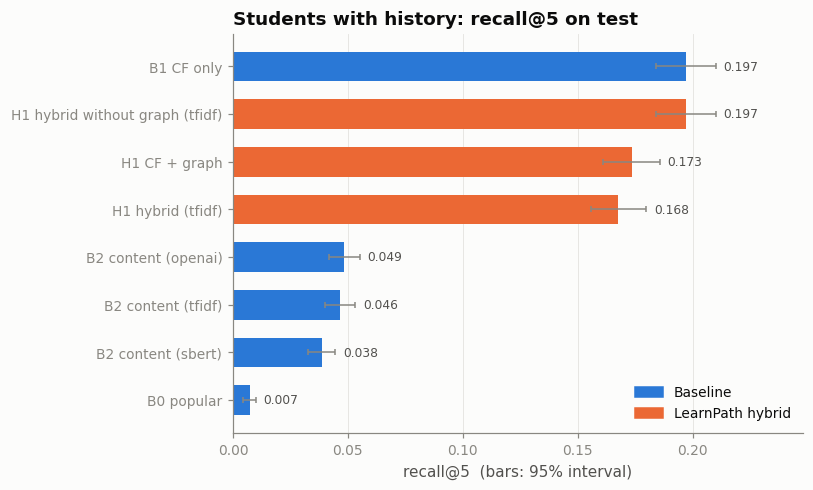

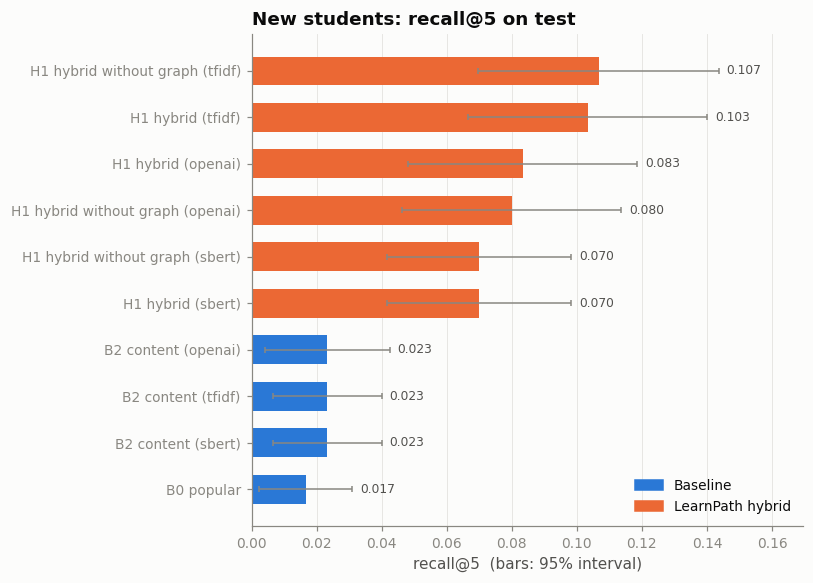

In [5]:
# Step 4: charts
from matplotlib.patches import Patch

def bar_chart(table, metric, title, fname, ci=None):
    t = table.sort_values(metric)
    fig, ax = plt.subplots(figsize=(7.5, 0.42 * len(t) + 1.2))
    colors = [plots.PALETTE[1] if i.startswith("H") else plots.PALETTE[0] for i in t.index]
    err = t[ci] if ci else 0 * t[metric]
    ax.barh(t.index, t[metric], color=colors, height=0.62,
            xerr=err if ci else None, error_kw={"ecolor": plots.MUTED, "elinewidth": 1, "capsize": 2})
    for y, (v, e) in enumerate(zip(t[metric], err)):
        ax.annotate(f"{v:.3f}", (v + e, y), xytext=(5, 0), textcoords="offset points",
                    va="center", fontsize=8, color=plots.INK_2)
    ax.set_xlim(0, (t[metric] + err).max() * 1.18)
    ax.legend(handles=[Patch(color=plots.PALETTE[0], label="Baseline"),
                       Patch(color=plots.PALETTE[1], label="LearnPath hybrid")], loc="lower right")
    ax.set_title(title)
    ax.set_xlabel(metric + ("  (bars: 95% interval)" if ci else ""))
    plots.horizontal_grid(ax)
    fig.tight_layout()
    plots.save(fig, fname)
    plt.show()

bar_chart(warm_table, "recall@5", "Students with history: recall@5 on test", "06_warm_recall", ci="recall@5_ci95")
bar_chart(cold_table, "recall@5", "New students: recall@5 on test", "06_cold_recall", ci="recall@5_ci95")

## Does the LLM rerank help?

Same students, same 20-course shortlist. "H1 shortlist top 5" keeps the shortlist order, and H2 lets the LLM choose. The ceiling column is how often the right course was in the shortlist at all.

`change_vs_shortlist` is the per-student difference in recall, with a 95% interval. When the LLM returns an ID outside the shortlist, that slot is filled from the shortlist, so `filled_share` counts those slots and `recall@5_llm_picks` counts only the LLM's own picks.

In [6]:
# Step 5: LLM vs shortlist, for each prompt version
checker = graph.PrereqChecker(PG, courses)
llm_runs = {}
for run, version in config.LLM_RUNS.items():
    for f in sorted(config.LLM_DIR.glob(f"rerank_*_{run}.jsonl")):
        df = llm.load_results(f)
        if not df.empty:
            llm_runs[(f.stem.split("_")[1], version)] = df
print("LLM runs found:", [f"{p} prompt {v} ({len(d)} answers)" for (p, v), d in llm_runs.items()])

llm_rows, llm_ops = [], []
for (provider, version), df in llm_runs.items():
    is_cold = df["student_id"].str.startswith("N")
    for group, mask, tr, studs_df in [("history", ~is_cold, truth, students),
                                      ("new", is_cold, cold_truth_test, cold)]:
        d = df[mask]
        if d.empty:
            continue
        hist_g = hist if group == "history" else {}
        h1 = {r.student_id: r.candidate_ids[:5] for r in d.itertuples()}
        h2 = {r.student_id: r.recs for r in d.itertuples()}
        ceiling = np.mean([len(set(r.candidate_ids) & set(tr[r.student_id])) / len(tr[r.student_id])
                           for r in d.itertuples()])
        s1, per1 = evaluate_lists(h1, tr, studs_df, courses, checker, hist_g)
        s2, per2 = evaluate_lists(h2, tr, studs_df, courses, checker, hist_g)
        diff = per2.set_index("student_id")["recall@5"] - per1.set_index("student_id")["recall@5"]
        # courses the LLM picked itself (filled slots have no reason)
        own = [len({c for c in r.recs if c in r.reasons} & set(tr[r.student_id])) / len(tr[r.student_id])
               for r in d.itertuples()]
        filled = sum(len([c for c in r.recs if c not in r.reasons]) for r in d.itertuples())
        for label, s in [("H1 shortlist top 5", s1), (f"H2 LLM {version} ({provider})", s2)]:
            row = {"group": group, "system": label, "students": s["students"],
                   "recall@5": s["recall@5"], "ci95": s["recall@5_ci95"], "ndcg@5": s["ndcg@5"],
                   "on_interest": s["on_interest_share"], "too_hard": s["too_hard_share"],
                   "prereq_violation": s["prereq_violation_share"], "shortlist_ceiling@20": ceiling}
            if label.startswith("H2"):
                row["change_vs_shortlist"] = diff.mean()
                row["change_ci95"] = 1.96 * diff.std() / np.sqrt(len(diff))
                row["filled_share"] = filled / (len(d) * config.TOP_K)
                row["recall@5_llm_picks"] = np.mean(own)
            llm_rows.append(row)
    llm_ops.append({"provider": provider, "model": df["model"].iloc[0], "prompt": version, "calls": len(df),
                    "failed_calls": int(df["error"].notna().sum()),
                    "invented_ids_caught": int(df["n_invalid"].sum()),
                    "repeats_caught": int(df["n_duplicate"].sum()),
                    "slots_filled": int(df["n_filled"].sum()),
                    "median_latency_s": df["latency_s"].median(),
                    "median_output_tokens": df["completion_tokens"].median(),
                    "cost_per_1000_recs_usd": df["cost_usd"].mean() * 1000,
                    "total_cost_usd": df["cost_usd"].sum()})

if llm_rows:
    llm_table = (pd.DataFrame(llm_rows).drop_duplicates(["group", "system"])
                 .sort_values(["group", "system"], key=lambda c: c.map({"history": 0, "new": 1}) if c.name == "group" else c)
                 .reset_index(drop=True))
    ops_table = pd.DataFrame(llm_ops).sort_values(["prompt", "provider"]).reset_index(drop=True)
    display(llm_table.round(3))
    display(ops_table.round(4))
    if llm_table["students"].min() < 50:
        print("Only a few students per group so far (trial run). Too few to compare models.")
else:
    print("No LLM results yet. Run notebook 05 first.")

LLM runs found: ['deepseek prompt v1 (400 answers)', 'openai prompt v1 (400 answers)', 'deepseek prompt v2 (400 answers)', 'openai prompt v2 (400 answers)']


,group,system,students,recall@5,ci95,ndcg@5,on_interest,too_hard,prereq_violation,shortlist_ceiling@20,change_vs_shortlist,change_ci95,filled_share,recall@5_llm_picks
0,history,H1 shortlist top 5,300,0.163,0.031,0.126,0.943,0.017,0.051,0.333,NaN,NaN,NaN,NaN
1,history,H2 LLM v1 (deepseek),300,0.100,0.026,0.073,0.964,0.001,0.067,0.333,-0.063,0.027,0.000,0.100
2,history,H2 LLM v1 (openai),300,0.107,0.026,0.090,0.955,0.001,0.038,0.333,-0.057,0.027,0.003,0.105
3,history,H2 LLM v2 (deepseek),300,0.108,0.026,0.086,0.968,0.001,0.053,0.333,-0.055,0.026,0.000,0.108
4,history,H2 LLM v2 (openai),300,0.132,0.028,0.101,0.947,0.006,0.038,0.333,-0.032,0.022,0.118,0.100
5,new,H1 shortlist top 5,100,0.103,0.037,0.106,0.404,0.000,0.066,0.157,NaN,NaN,NaN,NaN
6,new,H2 LLM v1 (deepseek),100,0.090,0.031,0.078,0.638,0.000,0.066,0.157,-0.013,0.026,0.000,0.090
7,new,H2 LLM v1 (openai),100,0.073,0.029,0.079,0.580,0.000,0.066,0.157,-0.030,0.031,0.000,0.073
8,new,H2 LLM v2 (deepseek),100,0.107,0.033,0.101,0.652,0.000,0.070,0.157,0.003,0.027,0.000,0.107
9,new,H2 LLM v2 (openai),100,0.093,0.032,0.092,0.554,0.000,0.082,0.157,-0.010,0.024,0.122,0.070


,provider,model,prompt,calls,failed_calls,invented_ids_caught,repeats_caught,slots_filled,median_latency_s,median_output_tokens,cost_per_1000_recs_usd,total_cost_usd
0,deepseek,deepseek-flash,v1,400,0,0,0,0,1.820,169.0,0.8226,0.3290
1,openai,gpt-4o-mini,v1,400,0,4,0,4,4.165,192.0,0.4198,0.1679
2,deepseek,deepseek-flash,v2,400,0,0,0,0,1.790,162.0,0.8954,0.3582
3,openai,gpt-4o-mini,v2,400,0,238,0,238,3.200,142.0,0.4325,0.1730


In [7]:
# Step 6: example explanations (what the student would actually read)
# same 3 students for every model and prompt, so they can be compared side by side
name = dict(zip(courses["course_id"], courses["name"]))
examples = []
if llm_runs:
    shared = set.intersection(*(set(d["student_id"]) for d in llm_runs.values()))
    pick = pd.Series(sorted(shared)).sample(n=min(3, len(shared)), random_state=config.SEED).tolist()
    for sid in pick:
        st = everyone.set_index("student_id").loc[sid]
        for (provider, version), df in llm_runs.items():
            r = df[df["student_id"] == sid].iloc[0]
            examples.append(f"### {sid} ({r['model']}, prompt {version})\nInterests: {st['stated_interests']} | "
                            f"level: {st['self_reported_level']} | {st['weekly_hours']:g} h/week\n")
            for cid in r["recs"]:
                examples.append(f"- **{name[cid]}**: {r['reasons'].get(cid, '(filled from shortlist)')}")
            examples.append("")
text = "\n".join(examples) if examples else "No LLM results yet."
(config.RESULTS / "llm_examples.md").write_text(text)
print(text[:6000])

### S0702 (deepseek-flash, prompt v1)
Interests: economics | level: Intermediate | 5 h/week

- **Economics of Money and Banking**: Builds directly on your macroeconomics foundation with monetary systems and banking, matching your intermediate level and reading-based learning.
- **Monetary Policy in the Asia Pacific**: Applies monetary policy concepts to real economies, extending your macro knowledge at a comfortable intermediate pace.
- **Trade, Immigration and Exchange Rates in a Globalized World**: Connects your macro and trade interests through exchange rates and globalization, fitting your 5-hour weekly reading schedule.
- **Introduction to Economic Theories**: Broadens your theoretical perspective on economic schools of thought, complementing your completed intermediate courses.
- **Local Economic Development**: Applies economics to local development policy, offering a coherent applied path after your theoretical foundation.

### S0702 (gpt-4o-mini, prompt v1)
Interests: economics

## Fairness check

Demographics aren't used for ranking, but I still compare H1 recall across regions and age bands. In this simulation they have no effect, so any gap here is noise. The check is for when real data comes in.

In [8]:
# Step 7: recall by region and age band, with a 95% interval per group
best = ex.best_space(params, spaces)
h1_label = f"H1 hybrid ({best})" if f"H1 hybrid ({best})" in lists_by_system else "H1 CF + graph"
print("System:", h1_label)
_, per = evaluate_lists(lists_by_system[h1_label], truth, students, courses)
per = per.merge(students[["student_id", "region", "age_band"]], on="student_id")
def summary(col, label):
    g = per.groupby(col)["recall@5"]
    return pd.DataFrame({"mean": g.mean(), "ci95": 1.96 * g.std() / np.sqrt(g.count()),
                         "count": g.count()}).assign(group=label)
fair = pd.concat([summary("region", "region"), summary("age_band", "age band")])
fair.round(3)

System: H1 hybrid (tfidf)


,mean,ci95,count,group
Europe,0.157,0.030,315,region
Latin America,0.134,0.036,176,region
Middle East & North Africa,0.167,0.034,252,region
North America,0.164,0.032,281,region
South Asia,0.194,0.031,337,region
Southeast Asia,0.173,0.027,442,region
Sub-Saharan Africa,0.165,0.037,197,region
18-24,0.159,0.019,737,age band
25-34,0.161,0.021,687,age band
35-44,0.190,0.030,331,age band


## Limitations

- The students are simulated, so these numbers compare the parts under my assumptions, not on real learners.
- Stated interests are topic names, which favors TF-IDF over embeddings.
- Prerequisites are inferred, and the skill tags are noisy.
- The LLM part is tested on 400 students, and recall doesn't measure the reasons or the study order.
- I wrote prompt v2 after seeing the v1 results. I only ran it once, but its numbers are still a bit optimistic.

In [9]:
# Step 8: save the result tables
warm_table.to_csv(config.RESULTS / "metrics_history.csv")
cold_table.to_csv(config.RESULTS / "metrics_new_students.csv")
fair.to_csv(config.RESULTS / "fairness.csv")
if llm_rows:
    llm_table.to_csv(config.RESULTS / "metrics_llm.csv", index=False)
    ops_table.to_csv(config.RESULTS / "llm_operations.csv", index=False)
print("Saved tables to", config.RESULTS)

Saved tables to /content/drive/MyDrive/LearnPath/results
